In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(
    "../data/processed/retail_sales_clean.csv"
)

In [3]:
#Converting Date columns into Date Coluumns
df["Order Date"] = pd.to_datetime(df["Order Date"])

df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [4]:
print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (9994, 27)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sales,Quantity,Discount,Profit,Order Year,Order Month,Order Day,Month Name,Shipping Days,Profit Margin
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,261.9600,2,0.00,41.9136,2016,11,8,November,3,16.00
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,731.9400,3,0.00,219.5820,2016,11,8,November,3,30.00
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,14.6200,2,0.00,6.8714,2016,6,12,June,4,47.00
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,957.5775,5,0.45,-383.0310,2015,10,11,October,7,-40.00
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,22.3680,2,0.20,2.5164,2015,10,11,October,7,11.25


In [5]:
#Calculating Business KPI (Key Performance Indicator)
total_sales = df["Sales"].sum()

total_profit = df["Profit"].sum()

total_orders = df["Order ID"].nunique()

total_quantity = df["Quantity"].sum()

profit_margin = (total_profit / total_sales) * 100

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Quantity Sold:", total_quantity)
print("Profit Margin:", round(profit_margin, 2), "%")


Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Quantity Sold: 37873
Profit Margin: 12.47 %


In [6]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Total Orders",
        "Total Quantity",
        "Profit Margin"
    ],
    "Value": [
        total_sales,
        total_profit,
        total_orders,
        total_quantity,
        profit_margin
    ]
})

kpi_summary

,Metric,Value
0,Total Sales,2.297201e+06
1,Total Profit,2.863970e+05
2,Total Orders,5.009000e+03
3,Total Quantity,3.787300e+04
4,Profit Margin,1.246722e+01


## Overall Business Performance

1. Total Sales: 2,297,200.86
2. Total Profit: 286,397.02
3. Total Orders: 5,009
4. Total Quantity Sold: 37,873
5. Profit Margin: 12.47%

### Observation
(To be completed using the calculated results.)

## Sales Analysis by Product Category
<b> Business question: Which product category generates the highest sales and profit?</b> 

Our dataset has three categories:
- Furniture
- Office Supplies
- Technology

In [7]:
# 1. Calculating sales by Category
category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).round(2)

category_analysis

,Total_Sales,Total_Profit,Total_Quantity
Category,,,
Furniture,741999.80,18451.27,8028
Office Supplies,719047.03,122490.80,22906
Technology,836154.03,145454.95,6939


In [8]:
# 2. Sorting Categories by Sales
category_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity
Category,,,
Technology,836154.03,145454.95,6939
Furniture,741999.80,18451.27,8028
Office Supplies,719047.03,122490.80,22906


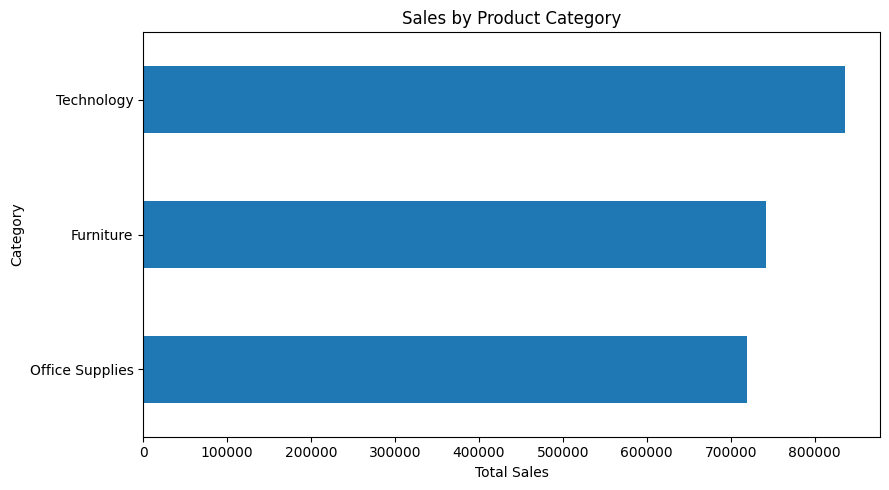

In [9]:
# Visualizing category Sales
plt.figure(figsize=(9, 5))

category_analysis["Total_Sales"].sort_values().plot(
    kind="barh"
)

plt.title("Sales by Product Category")
plt.xlabel("Total Sales")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

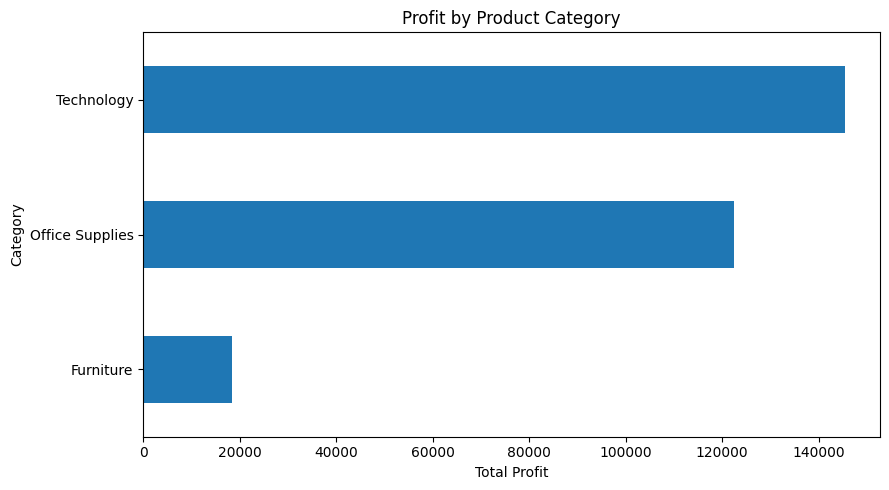

In [10]:
# Visualizing Category Profit
plt.figure(figsize=(9, 5))

category_analysis["Total_Profit"].sort_values().plot(
    kind="barh"
)

plt.title("Profit by Product Category")
plt.xlabel("Total Profit")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

## Product Category Analysis

### Key Findings

1. Technology generates the highest sales and profit.
2. Office Supplies generates the second-highest profit.
3. Furniture generates the lowest profit despite having
   the second-highest sales.

### Business Recommendations

1. Maintain the performance of Technology products.
2. Investigate the profitability of Furniture products.
3. Analyse discount and pricing strategies.
4. Explore opportunities to increase Office Supplies sales.

## Regional Sales Analysis

<b>Business question: Which geographical region generates the highest sales and profit?</b>

Our dataset contains four regions:
- Central
- East
- South
- West

In [11]:
#Calculating regional performance
region_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).round(2)

region_analysis

,Total_Sales,Total_Profit,Total_Quantity
Region,,,
Central,501239.89,39706.36,8780
East,678781.24,91522.78,10618
South,391721.90,46749.43,6209
West,725457.82,108418.45,12266


In [12]:
#Sorting by Sales
region_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity
Region,,,
West,725457.82,108418.45,12266
East,678781.24,91522.78,10618
Central,501239.89,39706.36,8780
South,391721.90,46749.43,6209


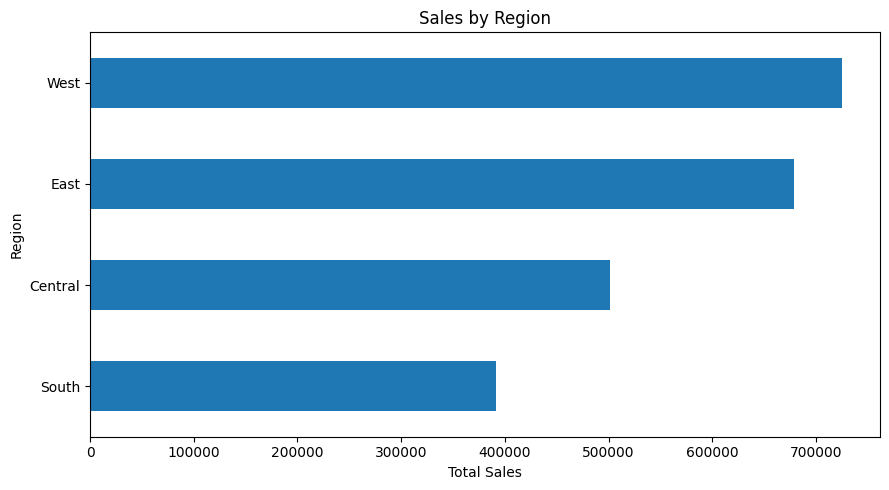

In [13]:
#Visualizing regional sales
plt.figure(figsize=(9, 5))

region_analysis["Total_Sales"].sort_values().plot(
    kind="barh"
)

plt.title("Sales by Region")
plt.xlabel("Total Sales")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

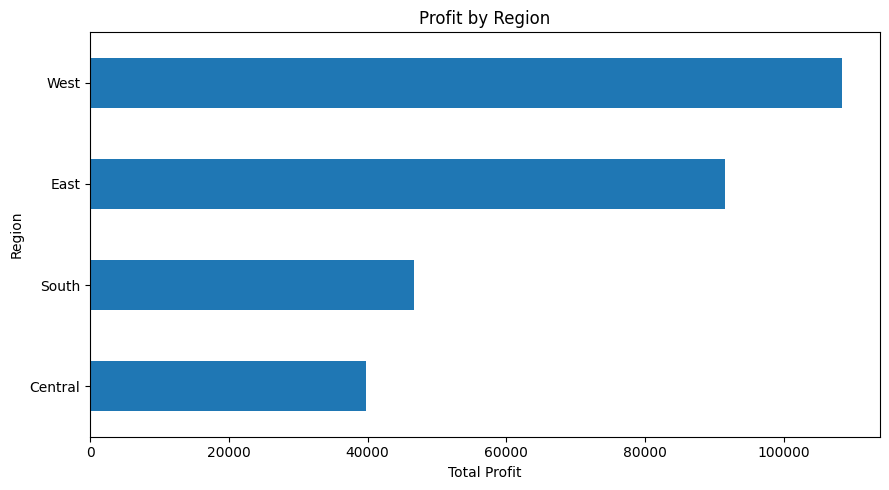

In [14]:
# Visualizing regional profit
plt.figure(figsize=(9, 5))

region_analysis["Total_Profit"].sort_values().plot(
    kind="barh"
)

plt.title("Profit by Region")
plt.xlabel("Total Profit")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

## Regional Sales Analysis

### Key Findings
1. West generates the highest sales and profit.
2. East is the second-highest performing region.
3. Central has higher sales than South but lower profit.
4. South generates the lowest sales.

### Business Recommendations
1. Maintain West region's performance.
2. Analyse successful strategies used in West.
3. Investigate Central's profitability.
4. Explore growth opportunities in South.

## Monthly Sales Trend Analysis

<b>Business question: How do sales change over time? Which months and years perform better?</b>

In [15]:
#Calculating monthly sales
monthly_sales = df.groupby(
    df["Order Date"].dt.to_period("M")
)["Sales"].sum()

monthly_sales

Order Date
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160


In [16]:
#Converting the index for plotting
monthly_sales.index = monthly_sales.index.to_timestamp()

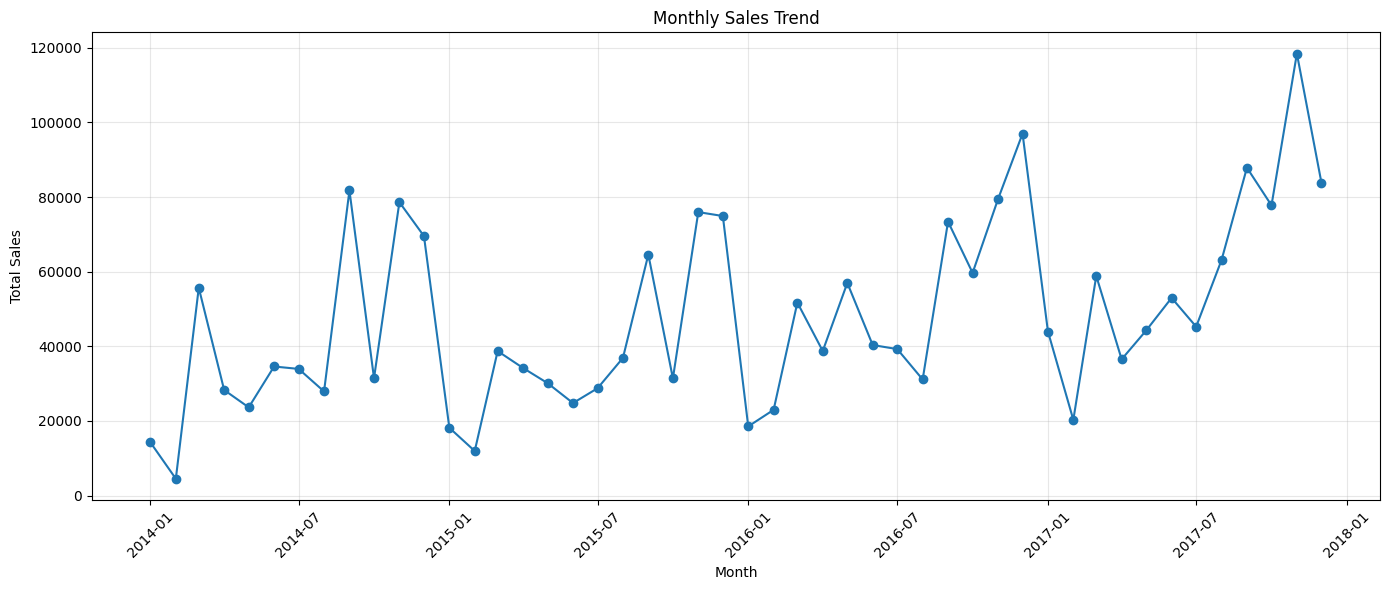

In [17]:
#Creating a line chart
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
#Finding the hightest and the lowest sales on the month
print(
    "Highest Sales Month:",
    monthly_sales.idxmax()
)

print(
    "Highest Monthly Sales:",
    round(monthly_sales.max(), 2)
)

print(
    "Lowest Sales Month:",
    monthly_sales.idxmin()
)

print(
    "Lowest Monthly Sales:",
    round(monthly_sales.min(), 2)
)

Highest Sales Month: 2017-11-01 00:00:00
Highest Monthly Sales: 118447.82
Lowest Sales Month: 2014-02-01 00:00:00
Lowest Monthly Sales: 4519.89


## Monthly Sales Trend Analysis

### Key Findings

1. Highest sales occurred in November 2017.
2. Lowest sales occurred in February 2014.
3. Monthly sales show considerable fluctuations.
4. Higher sales peaks are visible in later years.

### Business Recommendations

1. Investigate factors contributing to peak sales months.
2. Analyse seasonal purchasing patterns.
3. Plan inventory according to monthly demand.
4. Investigate months with unusually low sales.

## Discount vs Profit Analysis

<b>Business question: Does offering higher discounts affect the profitability of retail products?</b>

In [19]:
# Calculating average discount and profit
discount_analysis = df.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean")
).round(2)

discount_analysis

,Total_Sales,Total_Profit,Average_Profit
Discount,,,
0.00,1087908.47,320987.60,66.90
0.10,54369.35,9029.18,96.06
0.15,27558.52,1418.99,27.29
0.20,764594.37,90337.31,24.70
0.30,103226.66,-10369.28,-45.68
0.32,14493.46,-2391.14,-88.56
0.40,116417.78,-23057.05,-111.93
0.45,5484.97,-2493.11,-226.65
0.50,58918.54,-20506.43,-310.70


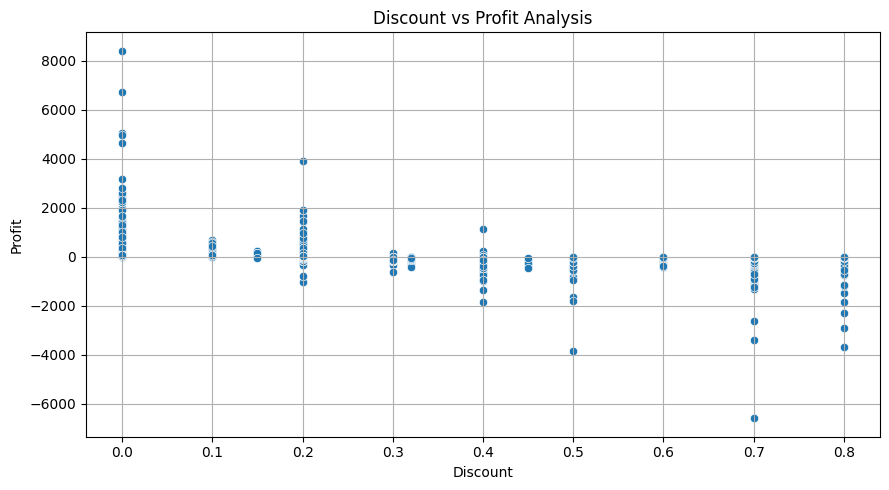

In [21]:
#Creating a scatter plot
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit"
)

plt.title("Discount vs Profit Analysis")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.tight_layout()
plt.grid()
plt.show()

In [22]:
# Calculating Correlation
correlation = df["Discount"].corr(df["Profit"])

print("Discount-Profit Correlation:", round(correlation, 3))

Discount-Profit Correlation: -0.219


## Discount vs Profit Analysis

### Key Findings

1. Discount-profit correlation is -0.219.
2. Zero-discount transactions generate the highest
   total profit.
3. 10% discount transactions have higher average
   profit than zero-discount transactions.
4. Higher discount levels show negative total profits
   in several discount groups.

### Business Recommendations

1. Review high-discount pricing strategies.
2. Monitor product profitability during promotions.
3. Evaluate discounts based on profit margins.
4. Avoid promotions that consistently generate losses.

## Top 10 Best-Selling Products

<b>Business question: Which products generate the highest sales for the business?</b>

In [23]:
#Calculating product performance
product_analysis = df.groupby("Product Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).round(2)

product_analysis.head()

,Total_Sales,Total_Profit,Total_Quantity
Product Name,,,
"""While you Were Out"" Message Book, One Form per Page",25.23,10.39,8
"#10 Gummed Flap White Envelopes, 100/Box",41.30,16.77,11
#10 Self-Seal White Envelopes,108.68,52.12,10
"#10 White Business Envelopes,4 1/8 x 9 1/2",488.90,223.14,32
"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",286.67,115.28,37


In [24]:
#Finding top 10 products by sales
top_10_products = product_analysis.sort_values(
    by="Total_Sales",
    ascending=False
).head(10)

top_10_products

,Total_Sales,Total_Profit,Total_Quantity
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.38,7753.04,31
Cisco TelePresence System EX90 Videoconferencing Unit,22638.48,-1811.08,6
HON 5400 Series Task Chairs for Big and Tall,21870.58,0.00,39
GBC DocuBind TL300 Electric Binding System,19823.48,2233.51,37
GBC Ibimaster 500 Manual ProClick Binding System,19024.50,760.98,48
Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88,38
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.90,4094.98,12
GBC DocuBind P400 Electric Binding System,17965.07,-1878.17,27


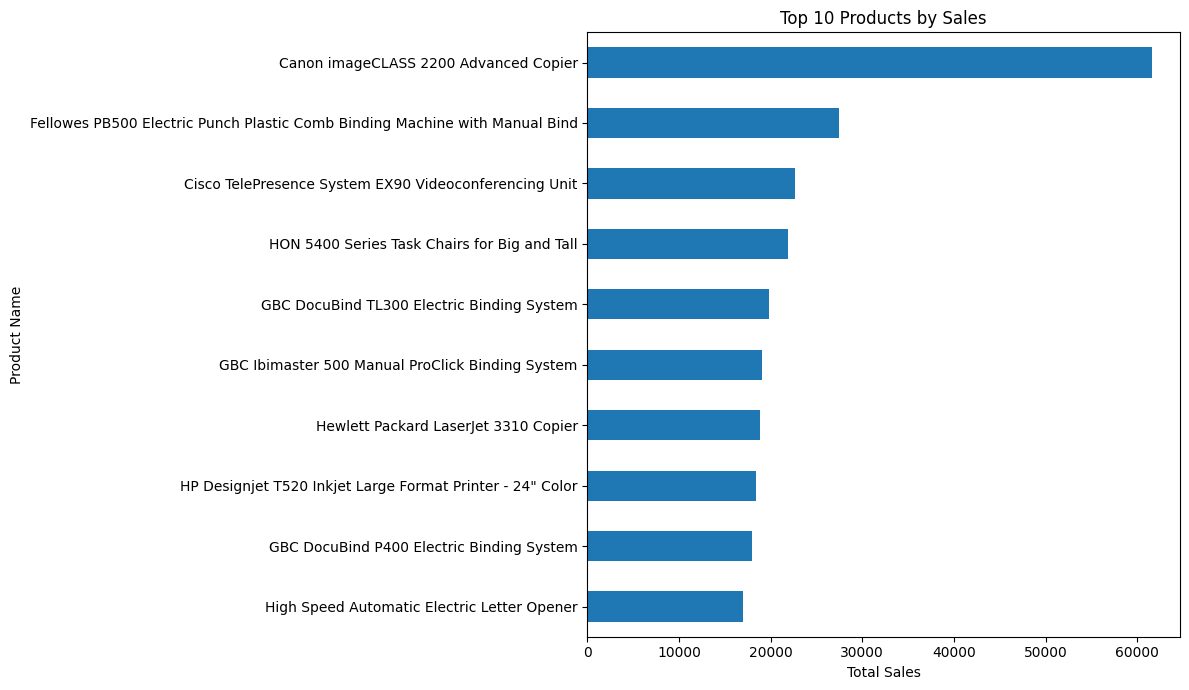

In [25]:
# Visualizing top 10 products
plt.figure(figsize=(12, 7))

top_10_products["Total_Sales"].sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")

plt.tight_layout()
plt.show()

In [26]:
#Finding the most profitavle product 
top_10_profit = product_analysis.sort_values(
    by="Total_Profit",
    ascending=False
).head(10)

top_10_profit

,Total_Sales,Total_Profit,Total_Quantity
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.38,7753.04,31
Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88,38
Canon PC1060 Personal Laser Copier,11619.83,4570.93,19
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.90,4094.98,12
Ativa V4110MDD Micro-Cut Shredder,7699.89,3772.95,11
"3D Systems Cube Printer, 2nd Generation, Magenta",14299.89,3717.97,11
Plantronics Savi W720 Multi-Device Wireless Headset System,9367.29,3696.28,24
Ibico EPK-21 Electric Binding System,15875.92,3345.28,13


## Top 10 Product Analysis

### Key Findings

1. Canon imageCLASS 2200 generates the highest sales.
2. Canon imageCLASS 2200 also generates the highest profit.
3. Some high-revenue products generate negative profit.
4. Product sales performance and profitability differ.

### Business Recommendations

1. Prioritise profitable products.
2. Investigate loss-making high-revenue products.
3. Review discount and pricing strategies.
4. Monitor product-level profitability regularly.

In [27]:
category_analysis.to_csv(
    "../reports/category_analysis.csv"
)

region_analysis.to_csv(
    "../reports/region_analysis.csv"
)

monthly_sales.to_csv(
    "../reports/monthly_sales.csv"
)

discount_analysis.to_csv(
    "../reports/discount_analysis.csv"
)

top_10_products.to_csv(
    "../reports/top_10_products.csv"
)

top_10_profit.to_csv(
    "../reports/top_10_profit.csv"
)

In [28]:
import os

os.listdir("../reports")

['discount_analysis.csv',
 'category_analysis.csv',
 'monthly_sales.csv',
 'top_10_products.csv',
 'region_analysis.csv',
 'top_10_profit.csv']

In [29]:
import unicodedata

# Create a copy of the cleaned dataset
df_mysql = df.copy()

# Convert special characters in text columns
# into ASCII-compatible text
for col in df_mysql.select_dtypes(include="object").columns:
    df_mysql[col] = df_mysql[col].apply(
        lambda x: unicodedata.normalize(
            "NFKD", str(x)
        ).encode("ascii", "ignore").decode("ascii")
        if pd.notna(x) else x
    )

# Save a separate CSV for MySQL
df_mysql.to_csv(
    "../data/processed/retail_sales_mysql.csv",
    index=False,
    encoding="utf-8"
)

print("MySQL-compatible CSV created!")
print("Rows:", df_mysql.shape[0])
print("Columns:", df_mysql.shape[1])

MySQL-compatible CSV created!
Rows: 9994
Columns: 27


In [30]:
import os

print(os.path.exists(
    "../data/processed/retail_sales_mysql.csv"
))

True


In [31]:
print(df_mysql.shape)

(9994, 27)
